# **Aprendizaje por refuerzos** - LunarLander (Gymnasium)

## Implementación de un agente DQN (Deep Q-Network): consigna

> **Cómo trabajar este cuaderno.** Hay **3 bloques marcados con `TODO`** repartidos
> por las secciones 6 a 11. Cada uno corta la ejecución con `NotImplementedError`
> hasta que lo completen. Todo lo demás (el entorno, la interfaz, las funciones de
> evaluación y entrenamiento, las gráficas de progreso y el GIF de la sección 9) ya
> está escrito y no hay que tocarlo.

> **Qué se entrega.** Este cuaderno completo y autocontenido, con el código y la
> salida de los experimentos realizados, y un **artículo en formato IEEE** de no más
> de 5 páginas con el informe. La discusión de los resultados va en el artículo, no
> en el cuaderno: la letra de la tarea detalla los puntos que tiene que cubrir.

### Objetivos:
1. Explorar el entorno `LunarLander-v3` de Gymnasium (estado continuo, acciones discretas)
2. Testear el agente aleatorio como implementación de referencia
3. Diseñar e implementar un agente DQN
4. Entrenar y evaluar el agente
5. Comparar el desempeño contra la implementación de referencia y visualizar la política aprendida
6. Medir con un estudio de ablación cuánto aporta cada componente de DQN

El requisito mínimo de la consigna es superar **10% de éxito** en evaluación.

El cuaderno se organiza en una interfaz `Agente`, las funciones `entrenar_agente` /
`evaluar_agente` y el agente DQN, aplicados a un problema de **estado continuo**.

## Copia de trabajo A — checkpoint del jueves

El original se conserva sin cambios. Leer `README_A.md` para instalación y ejecución.
El modo predeterminado es **piloto**, no la comparación final. La celda de controles
permite activar la comparación y las semillas adicionales. Secciones 10/11 diferidas;
la redacción e interpretación del informe corresponden al equipo.


## 1. Dependencias

| Paquete | Uso |
|---|---|
| `gymnasium[box2d]` | entorno `LunarLander-v3` (el extra `[box2d]` instala también el motor de física) |
| `torch` | red neuronal Q y optimización |
| `matplotlib` | gráficas de progreso y GIF de la política final |

In [1]:
# En local: usar .venv (ver README_A.md). En Colab, descomentar:
# %pip install "gymnasium[box2d]>=1.0" torch matplotlib ipykernel nbformat nbclient
import os
import sys
if sys.platform.startswith('linux') and not os.environ.get('DISPLAY'):
    os.environ['SDL_VIDEODRIVER'] = 'dummy'
print(f"kernel: {sys.executable}")


kernel: /Users/thiago.rivas/Documents/varios/FING/aprendaut/laboratorioAprendAut2/.venv/bin/python


In [2]:
# Importar las bibliotecas
import random
import time
from abc import ABC, abstractmethod
from collections import deque, namedtuple

import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

SEMILLA = 42
random.seed(SEMILLA)
np.random.seed(SEMILLA)
torch.manual_seed(SEMILLA)

print(f"gymnasium {gym.__version__} | torch {torch.__version__} | "
      f"dispositivo: {'cuda' if torch.cuda.is_available() else 'cpu'}")

gymnasium 1.4.0 | torch 2.14.1 | dispositivo: cpu


In [3]:
# El piloto es descartable; no cuenta como evidencia A0/A1.
# Cambiar a "comparison" después de revisar el piloto; ambos usan agentes nuevos.
MODO = os.environ.get("DQN_MODE", "pilot")
assert MODO in {"pilot", "comparison"}
RUN_FINAL_EXPERIMENTS = False
RUN_GIF = False
EPISODIOS = 20 if MODO == "pilot" else 300
EPISODIOS_EVAL = 10 if MODO == "pilot" else 200
SEMILLAS_ENTRENAMIENTO = [42]  # Agregar 1042 solo si alcanza el tiempo.
MAX_PASOS = 1000
SEMILLA_EVAL = 10_000
HILOS_CPU = 1
torch.set_num_threads(HILOS_CPU)
CONFIGURACIONES = {"A0": {"hidden_dims": (64, 64), "lr": 1e-3},
                   "A1": {"hidden_dims": (128, 128), "lr": 5e-4}}
# El piloto mide A0 y un agente sin red objetivo; la comparación mide A0 y A1.
CONFIGS_ACTIVAS = {"pilot_A0": CONFIGURACIONES["A0"]} if MODO == "pilot" else CONFIGURACIONES
print(f"Modo {MODO}: {EPISODIOS} episodios; evaluación {EPISODIOS_EVAL}; CPU/{HILOS_CPU} hilo")


Modo comparison: 300 episodios; evaluación 200; CPU/1 hilo


## 2. El entorno LunarLander-v3

El objetivo es posar el módulo lunar sobre la plataforma de aterrizaje (siempre en
las coordenadas `(0, 0)`) de forma suave y sin volcarlo.

**Espacio de observación** (`Box(8,)`, continuo):

| Índice | Variable | Significado | Rango |
|---|---|---|---|
| 0 | `x` | posición horizontal respecto de la plataforma | ±2.5 |
| 1 | `y` | altura respecto de la plataforma | ±2.5 |
| 2 | `vx` | velocidad horizontal | ±10 |
| 3 | `vy` | velocidad vertical | ±10 |
| 4 | `θ` | ángulo del módulo | ±2π |
| 5 | `ω` | velocidad angular | ±10 |
| 6 | `c_izq` | 1 si la pata izquierda toca el suelo | 0 o 1 |
| 7 | `c_der` | 1 si la pata derecha toca el suelo | 0 o 1 |

**Espacio de acciones** (`Discrete(4)`): `0` no hacer nada, `1` motor lateral
izquierdo, `2` motor principal, `3` motor lateral derecho.

**Recompensa**, `+10` por cada pata en contacto con el suelo, `−0.3` por cada paso en que se enciende
el motor principal y `−0.03` por cada paso en que se enciende uno lateral. Al final,
`+100` o `−100` según cómo termine el episodio.

**Fin del episodio.** Hay dos casos:

* **Termina** cuando el módulo se estrella o sale de la pantalla (`|x| ≥ 1`), lo que
  da `−100`, o cuando queda quieto sobre el suelo, lo que da `+100`.
* **Se trunca** a los 1000 pasos, por el límite de tiempo que `gym.make` agrega con
  el *wrapper* `TimeLimit`. Truncar no significa que el episodio haya terminado mal:
  simplemente se acabó el presupuesto.

**Criterio de éxito.** La documentación considera resuelto un episodio que acumula
**al menos 200 puntos**. Se usa ese umbral para definir la *tasa de éxito*
(proporción de episodios con recompensa ≥ 200), que es la métrica que se reporta.

In [4]:
# Explorar el entorno LunarLander
env = gym.make('LunarLander-v3')

print("Información del entorno LunarLander-v3:")
print(f"Espacio de observación: {env.observation_space}")
print(f"Espacio de acción:      {env.action_space}")
print(f"Rango de observación:   {env.observation_space.low}")
print(f"                        {env.observation_space.high}")

estado, _ = env.reset(seed=SEMILLA)
print(f"\nEstado inicial: {np.round(estado, 3)}")
print(f"Forma del estado: {estado.shape}, tipo: {estado.dtype}")

accion = env.action_space.sample()
siguiente_estado, recompensa, terminado, truncado, info = env.step(accion)
print(f"\nAcción aleatoria: {accion}")
print(f"Estado siguiente: {np.round(siguiente_estado, 3)}")
print(f"Recompensa: {recompensa:.3f}")
print(f"Terminado: {terminado}, Truncado: {truncado}")

env.close()

Información del entorno LunarLander-v3:
Espacio de observación: Box([ -2.5        -2.5       -10.        -10.         -6.2831855 -10.
  -0.         -0.       ], [ 2.5        2.5       10.        10.         6.2831855 10.
  1.         1.       ], (8,), float32)
Espacio de acción:      Discrete(4)
Rango de observación:   [ -2.5        -2.5       -10.        -10.         -6.2831855 -10.
  -0.         -0.       ]
                        [ 2.5        2.5       10.        10.         6.2831855 10.
  1.         1.       ]

Estado inicial: [ 0.002  1.418  0.233  0.32  -0.003 -0.053  0.     0.   ]
Forma del estado: (8,), tipo: float32

Acción aleatoria: 2
Estado siguiente: [ 0.004  1.426  0.217  0.344 -0.006 -0.067  0.     0.   ]
Recompensa: -2.497
Terminado: False, Truncado: False


La celda siguiente permite jugar el entorno con el teclado: **W/↑** enciende el motor
principal, **A/←** y **D/→** mueven a los costados, **Q** o **ESC** salen. Sirve
para entender la complejidad del problema.

La llamada queda comentada porque es un bucle que no termina solo: hay que
descomentarla a mano.

In [5]:
def jugar_lunar_lander():
    """Juego interactivo. Controles: W/↑ motor principal, A/← mover a la izquierda,
    D/→ mover a la derecha, ninguna tecla = sin empuje, Q/ESC salir.
    """
    import pygame

    pygame.display.quit()           # obliga a SDL a releer el controlador al reiniciar
    pygame.display.init()
    if pygame.display.get_driver() in ('dummy', 'offscreen'):
        raise RuntimeError(
            'SDL no encontró pantalla. Sin ventana el bucle no recibiría teclas y '
            'colgaría el kernel: hay que correr esta celda en Jupyter local.')

    env = gym.make('LunarLander-v3', render_mode='human')
    env.reset(seed=SEMILLA)
    reloj = pygame.time.Clock()
    recompensa_total = 0.0
    ejecutando = True

    try:
        while ejecutando:
            for evento in pygame.event.get():
                if evento.type == pygame.QUIT or (
                        evento.type == pygame.KEYDOWN
                        and evento.key in (pygame.K_q, pygame.K_ESCAPE)):
                    ejecutando = False

            teclas = pygame.key.get_pressed()
            if teclas[pygame.K_a] or teclas[pygame.K_LEFT]:
                accion = 3                      # motor izq
            elif teclas[pygame.K_d] or teclas[pygame.K_RIGHT]:
                accion = 1                      # motor der
            elif teclas[pygame.K_w] or teclas[pygame.K_UP]:
                accion = 2                      # motor principal
            else:
                accion = 0                      # no hacer nada

            _, recompensa, terminado, truncado, _ = env.step(accion)
            recompensa_total += recompensa

            if terminado or truncado:
                print(f"Episodio terminado. Recompensa total: {recompensa_total:.1f}")
                recompensa_total = 0.0
                env.reset()

            reloj.tick(50)
    finally:
        env.close()
        pygame.quit()


# Descomentar para jugar (es un bucle interactivo y no termina solo).
# jugar_lunar_lander()

## 3. Interfaz de los agentes

Un agente sabe `elegir_accion` a partir de una observación y `aprender` de una
transición. `elegir_accion` recibe además `explorar`: con `explorar=False` el agente
devuelve la acción que considera mejor, sin exploración; así lo llaman la evaluación
y la grabación del GIF. El agente aleatorio implementa esa interfaz y es la implementación de
referencia contra la que se compara el DQN.

In [6]:
class Agente(ABC):

    @abstractmethod
    def elegir_accion(self, estado, explorar=True):
        """Elige una acción dada una observación. Con `explorar=False`, sin
        exploración: la acción que el agente considera mejor."""
        pass

    @abstractmethod
    def aprender(self, estado, accion, recompensa, siguiente_estado, terminado):
        """Aprende de la experiencia."""
        pass

    def fin_episodio(self):
        """Callback opcional que el bucle de entrenamiento invoca al terminar cada
        episodio."""
        pass


class AgenteAleatorio(Agente):
    """Agente aleatorio que elige acciones al azar. Es la implementación de referencia."""

    def __init__(self, espacio_acciones, semilla=None):
        self.espacio_acciones = espacio_acciones
        if semilla is not None:
            # El espacio de acciones tiene su propio RNG y no lo alcanzan random.seed
            # ni np.random.seed: sin fijarle la semilla acá, el agente aleatorio no es reproducible.
            espacio_acciones.seed(semilla)

    def elegir_accion(self, estado, explorar=True):
        return self.espacio_acciones.sample()   # no tiene otra política que el azar

    def aprender(self, estado, accion, recompensa, siguiente_estado, terminado):
        pass  # El agente aleatorio no aprende


# Probar el AgenteAleatorio
env = gym.make('LunarLander-v3')
agente_aleatorio = AgenteAleatorio(env.action_space, semilla=SEMILLA)
estado, _ = env.reset(seed=SEMILLA)
accion = agente_aleatorio.elegir_accion(estado)
print(f"✓ AgenteAleatorio creado y probado. Acción: {accion}")
env.close()

✓ AgenteAleatorio creado y probado. Acción: 0


## 4. Función de evaluación

`evaluar_agente` corre `num_episodios` episodios completos **sin aprender** y
resume el desempeño. Un episodio se considera **exitoso** si la recompensa
acumulada es **≥ 200**, el umbral de "resuelto" que define Gymnasium para este
entorno.

Las acciones se piden sin exploración (`explorar=False`): la exploración es parte
del entrenamiento, no de la política que se quiere medir.

In [7]:
# Función de evaluación de agentes
UMBRAL_EXITO = 200.0   # recompensa a partir de la cual Gymnasium considera el episodio resuelto


def evaluar_agente(agente, env, num_episodios=100, umbral_exito=UMBRAL_EXITO, semilla=None):
    """
    Evalúa el rendimiento de un agente a lo largo de múltiples episodios.

    Args:
        agente: El agente a evaluar
        env: El entorno
        num_episodios: Número de episodios a ejecutar
        umbral_exito: Recompensa mínima para considerar exitoso un episodio
        semilla: Si se indica, se usan semillas deterministas (semilla + i) para
                 que la comparación entre agentes use los mismos escenarios

    Returns:
        dict: Resultados de la evaluación
    """
    recompensas_totales = []
    for episodio in range(num_episodios):
        estado, _ = env.reset(seed=None if semilla is None else semilla + episodio)
        recompensa_total = 0.0

        while True:
            accion = agente.elegir_accion(estado, explorar=False)
            estado, recompensa, terminado, truncado, _ = env.step(accion)
            recompensa_total += recompensa

            if terminado or truncado:
                break

        recompensas_totales.append(recompensa_total)

    recompensas_totales = np.array(recompensas_totales)
    exitos = int((recompensas_totales >= umbral_exito).sum())

    return {
        'recompensas_totales': recompensas_totales,
        'exitos': exitos,
        'tasa_exito': exitos / num_episodios,
        'recompensa_promedio': float(recompensas_totales.mean()),
        'desv_estandar': float(recompensas_totales.std()),
        'recompensa_mediana': float(np.median(recompensas_totales)),
    }


def imprimir_resultados_evaluacion(resultados, nombre_agente):
    """Imprime los resultados de evaluación con formato."""
    print(f"\n{nombre_agente} - Resultados de evaluación:")
    print(f"Tasa de éxito (R ≥ {UMBRAL_EXITO:.0f}): {resultados['tasa_exito']:.1%}")
    print(f"Recompensa promedio: {resultados['recompensa_promedio']:.2f}")
    print(f"Recompensa mediana:  {resultados['recompensa_mediana']:.2f}")
    print(f"Desviación estándar: {resultados['desv_estandar']:.2f}")
    print(f"Total de éxitos: {resultados['exitos']} / {len(resultados['recompensas_totales'])}")


# Implementación de referencia: evaluar el agente aleatorio
env = gym.make('LunarLander-v3')
agente_aleatorio = AgenteAleatorio(env.action_space, semilla=SEMILLA)
resultados_aleatorio = evaluar_agente(agente_aleatorio, env, num_episodios=EPISODIOS_EVAL, semilla=SEMILLA_EVAL)
imprimir_resultados_evaluacion(resultados_aleatorio, "Agente aleatorio")
env.close()



Agente aleatorio - Resultados de evaluación:
Tasa de éxito (R ≥ 200): 0.0%
Recompensa promedio: -183.17
Recompensa mediana:  -149.80
Desviación estándar: 111.96
Total de éxitos: 0 / 200


## 5. Función de entrenamiento

`entrenar_agente` corre `num_episodios` episodios y, en cada paso, le pasa la
transición al agente con `aprender`, con el indicador `terminado` real (sin
mezclarlo con `truncado`: truncar por tiempo no significa que el valor futuro sea 0).
Al final de cada episodio invoca `agente.fin_episodio()`.

Se agrega además un criterio de parada temprana (`umbral_resolucion`) sobre la
media móvil de 100 episodios, que es el criterio estándar para este entorno.

In [8]:
# Función de entrenamiento de agentes
def entrenar_agente(agente, env, num_episodios=1000, max_pasos=1000, verbose=True,
                    umbral_resolucion=None, semilla=None):
    """
    Entrena un agente en el entorno.

    Args:
        agente: El agente a entrenar
        env: El entorno
        num_episodios: Número de episodios de entrenamiento
        max_pasos: Máximo de pasos por episodio
        verbose: Si imprimir el progreso
        umbral_resolucion: Si se indica, corta cuando la media de las últimas 100
                           recompensas alcanza ese valor
        semilla: Semilla base para los reset (reproducibilidad)

    Returns:
        (list, list): recompensas y longitudes de cada episodio
    """
    recompensas_episodios = []
    longitudes_episodios = []
    cada = max(1, num_episodios // 20)
    t_inicio = time.time()

    for episodio in range(num_episodios):
        estado, _ = env.reset(seed=None if semilla is None else semilla + episodio)
        recompensa_total = 0.0
        pasos = 0

        for paso in range(max_pasos):
            accion = agente.elegir_accion(estado)
            siguiente_estado, recompensa, terminado, truncado, _ = env.step(accion)

            # `terminado` (y no `terminado or truncado`) es lo que corta el
            # bootstrapping: si el episodio se trunca por tiempo, el valor futuro
            # del estado siguiente sigue siendo válido.
            agente.aprender(estado, accion, recompensa, siguiente_estado, terminado)

            estado = siguiente_estado
            recompensa_total += recompensa
            pasos += 1

            if terminado or truncado:
                break

        agente.fin_episodio()
        recompensas_episodios.append(recompensa_total)
        longitudes_episodios.append(pasos)
        media_100 = np.mean(recompensas_episodios[-100:])

        if verbose and (episodio + 1) % cada == 0:
            print(f"Episodio {episodio + 1:5d} | Recompensa media (100 ep): {media_100:8.2f} "
                  f"| Longitud media: {np.mean(longitudes_episodios[-100:]):6.1f} "
                  f"| epsilon: {getattr(agente, 'epsilon', 0.0):.3f} "
                  f"| {time.time() - t_inicio:5.0f}s", flush=True)

        if umbral_resolucion is not None and len(recompensas_episodios) >= 100 and media_100 >= umbral_resolucion:
            print(f"\n✓ Entorno resuelto en {episodio + 1} episodios "
                  f"(recompensa media de los últimos 100: {media_100:.2f})", flush=True)
            break

    print(f"Tiempo total de entrenamiento: {time.time() - t_inicio:.0f}s")
    return recompensas_episodios, longitudes_episodios


def media_movil(valores, ventana=100):
    """Media móvil causal, para suavizar las curvas de aprendizaje."""
    valores = np.asarray(valores, dtype=float)
    return np.array([valores[max(0, i - ventana + 1):i + 1].mean() for i in range(len(valores))])


def graficar_progreso_entrenamiento(recompensas_episodios, longitudes_episodios,
                                    titulo="Progreso de entrenamiento", ventana=100):
    """Grafica el progreso del entrenamiento."""
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

    ax1.plot(recompensas_episodios, alpha=0.3, linewidth=0.8, label="Recompensa por episodio")
    ax1.plot(media_movil(recompensas_episodios, ventana), linewidth=2,
             label=f"Media móvil ({ventana} ep)")
    ax1.axhline(UMBRAL_EXITO, color='green', linestyle='--', linewidth=1, label="Umbral de éxito (200)")
    ax1.axhline(0, color='black', linewidth=0.5)
    ax1.set_title(f"{titulo} - Recompensas")
    ax1.set_xlabel("Episodio")
    ax1.set_ylabel("Recompensa")
    ax1.legend(loc="lower right", fontsize=8)
    ax1.grid(True, alpha=0.3)

    ax2.plot(longitudes_episodios, alpha=0.3, linewidth=0.8)
    ax2.plot(media_movil(longitudes_episodios, ventana), linewidth=2)
    ax2.set_title(f"{titulo} - Longitud de los episodios")
    ax2.set_xlabel("Episodio")
    ax2.set_ylabel("Pasos")
    ax2.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()


print("✓ Funciones de entrenamiento definidas")

✓ Funciones de entrenamiento definidas


## 6. El agente DQN

La celda siguiente define el agente DQN a implementar.


In [9]:
# Toda la implementación del agente permanece dentro de AgenteDQN.
class AgenteDQN(Agente):
    """DQN con replay uniforme y copia dura opcional de la red objetivo."""

    def __init__(self, estado_space, accion_space, semilla=None,
                 hidden_dims=(64, 64), lr=1e-3, use_target=True,
                 gamma=0.99, replay_capacity=50_000, batch_size=64,
                 learning_starts=1000, train_frequency=4, target_sync_steps=1000,
                 epsilon_start=1.0, epsilon_end=0.05, epsilon_decay_episodes=200,
                 gradient_clip=10.0, device="cpu"):
        if len(hidden_dims) != 2 or any(h <= 0 for h in hidden_dims):
            raise ValueError("Se requieren dos capas ocultas de tamaño positivo")
        if not (0 <= gamma <= 1 and 0 <= epsilon_end <= epsilon_start <= 1):
            raise ValueError("Descuento o epsilon inválido")
        if min(batch_size, learning_starts, train_frequency, target_sync_steps,
               epsilon_decay_episodes) <= 0 or replay_capacity < batch_size:
            raise ValueError("Capacidad, frecuencias o tamaño de batch inválidos")
        if lr <= 0 or gradient_clip <= 0:
            raise ValueError("lr y gradient_clip deben ser positivos")
        if semilla is not None:
            random.seed(semilla)
            np.random.seed(semilla)
            torch.manual_seed(semilla)
            accion_space.seed(semilla)
        self.accion_space = accion_space
        self.device = torch.device(device)
        self.use_target = use_target
        self.gamma = gamma
        self.batch_size = batch_size
        self.learning_starts = learning_starts
        self.train_frequency = train_frequency
        self.target_sync_steps = target_sync_steps
        self.epsilon_start, self.epsilon_end = epsilon_start, epsilon_end
        self.epsilon_decay_episodes = epsilon_decay_episodes
        self.gradient_clip = gradient_clip
        self.epsilon = epsilon_start
        self.env_steps = self.optimizer_updates = self.completed_episodes = 0
        self.last_loss = None
        self.memoria = deque(maxlen=replay_capacity)
        dims = (int(np.prod(estado_space.shape)), *hidden_dims, accion_space.n)
        capas = []
        for i in range(len(dims) - 1):
            capas.append(nn.Linear(dims[i], dims[i + 1]))
            if i < len(dims) - 2:
                capas.append(nn.ReLU())
        self.red_q = nn.Sequential(*capas).to(self.device)
        if use_target:
            import copy
            self.red_objetivo = copy.deepcopy(self.red_q)
            self.red_objetivo.requires_grad_(False)
            self.red_objetivo.eval()
        self.optimizador = optim.Adam(self.red_q.parameters(), lr=lr,
                                      betas=(0.9, 0.999), eps=1e-8, weight_decay=0)

    def elegir_accion(self, estado, explorar=True):
        # El cortocircuito evita consumir RNG de exploración al evaluar.
        if explorar and random.random() < self.epsilon:
            return int(self.accion_space.sample())
        with torch.no_grad():
            tensor = torch.as_tensor(estado, dtype=torch.float32, device=self.device).reshape(1, -1)
            return int(self.red_q(tensor).argmax(dim=1).item())

    def _calcular_objetivos(self, siguientes, recompensas, terminados):
        with torch.no_grad():
            red = self.red_objetivo if self.use_target else self.red_q
            valores = red(siguientes).max(dim=1).values
            return recompensas + self.gamma * (~terminados).float() * valores

    def _actualizar_red(self):
        transiciones = random.sample(self.memoria, self.batch_size)
        estados, acciones, recompensas, siguientes, terminados = zip(*transiciones)
        estados = torch.as_tensor(np.stack(estados), dtype=torch.float32, device=self.device)
        siguientes = torch.as_tensor(np.stack(siguientes), dtype=torch.float32, device=self.device)
        acciones = torch.as_tensor(acciones, dtype=torch.int64, device=self.device).unsqueeze(1)
        recompensas = torch.as_tensor(recompensas, dtype=torch.float32, device=self.device)
        terminados = torch.as_tensor(terminados, dtype=torch.bool, device=self.device)
        elegidos = self.red_q(estados).gather(1, acciones).squeeze(1)
        objetivos = self._calcular_objetivos(siguientes, recompensas, terminados)
        loss = F.smooth_l1_loss(elegidos, objetivos, beta=1.0, reduction="mean")
        self.optimizador.zero_grad(set_to_none=True)
        loss.backward()
        nn.utils.clip_grad_norm_(self.red_q.parameters(), self.gradient_clip)
        self.optimizador.step()
        self.optimizer_updates += 1
        self.last_loss = float(loss.detach().cpu())

    def aprender(self, estado, accion, recompensa, siguiente_estado, terminado):
        self.memoria.append((np.array(estado, dtype=np.float32, copy=True), int(accion),
                             float(recompensa), np.array(siguiente_estado, dtype=np.float32, copy=True),
                             bool(terminado)))
        self.env_steps += 1
        if (self.env_steps >= self.learning_starts and len(self.memoria) >= self.batch_size
                and self.env_steps % self.train_frequency == 0):
            self._actualizar_red()
        if self.use_target and self.env_steps % self.target_sync_steps == 0:
            self.red_objetivo.load_state_dict(self.red_q.state_dict())

    def fin_episodio(self):
        self.completed_episodes += 1
        self.epsilon = max(self.epsilon_end, self.epsilon_start -
                           (self.epsilon_start - self.epsilon_end) *
                           min(self.completed_episodes / self.epsilon_decay_episodes, 1.0))


In [10]:
# Comprobaciones de semántica; usan agentes descartables, no A0/A1.
def verificar_dqn():
    import copy
    env = gym.make("LunarLander-v3")
    try:
        def nuevo(**kw):
            return AgenteDQN(env.observation_space, env.action_space, semilla=7,
                             batch_size=64, learning_starts=64, target_sync_steps=68, **kw)
        a = nuevo()
        assert a.red_q(torch.zeros(64, 8)).shape == (64, 4)
        for p, t in zip(a.red_q.parameters(), a.red_objetivo.parameters()):
            assert torch.equal(p, t) and p.data_ptr() != t.data_ptr()
        inicial = copy.deepcopy(a.red_q.state_dict())
        s = np.zeros(8, dtype=np.float32)
        for i in range(64):
            a.aprender(s, i % 4, 2.0, s + 0.1, i % 2 == 0)
        assert a.optimizer_updates == 1 and np.isfinite(a.last_loss)
        assert any(not torch.equal(inicial[k], v) for k, v in a.red_q.state_dict().items())
        assert all(torch.equal(inicial[k], v) for k, v in a.red_objetivo.state_dict().items())
        assert all(p.grad is None for p in a.red_objetivo.parameters())
        # gather selecciona la acción correcta y conserva la forma [B].
        q = a.red_q(torch.zeros(64, 8))
        indices = torch.arange(64) % 4
        seleccionados = q.gather(1, indices[:, None]).squeeze(1)
        assert seleccionados.shape == (64,) and torch.equal(seleccionados, q[torch.arange(64), indices])
        objetivos = a._calcular_objetivos(torch.zeros(64, 8), torch.ones(64), torch.zeros(64, dtype=torch.bool))
        assert objetivos.shape == (64,) and not objetivos.requires_grad
        # Valor conocido: terminal=reward; no terminal (incluida truncación)=reward+gamma*3.
        with torch.no_grad():
            for p in a.red_objetivo.parameters():
                p.zero_()
            a.red_objetivo[-1].bias.fill_(3)
        y = a._calcular_objetivos(torch.zeros(2, 8), torch.tensor([2., 2.]), torch.tensor([True, False]))
        assert torch.allclose(y, torch.tensor([2., 2. + a.gamma * 3]))
        assert not y.requires_grad
        for _ in range(4):
            a.aprender(s, 0, 1, s, False)
        assert all(torch.equal(p, t) for p, t in zip(a.red_q.parameters(), a.red_objetivo.parameters()))
        # Replay guarda copias, aunque el llamador reutilice la observación.
        origen = np.ones(8, dtype=np.float32)
        a.aprender(origen, 0, 1, origen, False)
        origen[:] = 99
        assert np.all(a.memoria[-1][0] == 1) and np.all(a.memoria[-1][3] == 1)
        a.fin_episodio()
        assert np.isclose(a.epsilon, 1 - .95 / 200)
        for _ in range(199):
            a.fin_episodio()
        assert np.isclose(a.epsilon, .05)
        estado_antes = (a.epsilon, len(a.memoria), a.env_steps, a.optimizer_updates, a.completed_episodes)
        pesos_antes = copy.deepcopy(a.red_q.state_dict())
        rng = (random.getstate(), copy.deepcopy(np.random.get_state()), torch.get_rng_state().clone(),
               copy.deepcopy(env.action_space.np_random.bit_generator.state))
        for _ in range(10):
            a.elegir_accion(s, explorar=False)
        assert estado_antes == (a.epsilon, len(a.memoria), a.env_steps, a.optimizer_updates, a.completed_episodes)
        assert all(torch.equal(pesos_antes[k], v) for k, v in a.red_q.state_dict().items())
        assert random.getstate() == rng[0]
        assert np.array_equal(np.random.get_state()[1], rng[1][1])
        assert torch.equal(torch.get_rng_state(), rng[2])
        assert env.action_space.np_random.bit_generator.state == rng[3]
        sin_objetivo = nuevo(use_target=False)
        for _ in range(68):
            sin_objetivo.aprender(s, 0, 1, s, False)
        assert not hasattr(sin_objetivo, "red_objetivo")
        assert sin_objetivo.optimizer_updates == 2 and np.isfinite(sin_objetivo.last_loss)
        # Dos ejecuciones cortas reales con igual semilla deben coincidir en CPU.
        corridas = []
        for _ in range(2):
            b = nuevo()
            r, longitudes = entrenar_agente(b, env, num_episodios=2, max_pasos=80, semilla=7, verbose=False)
            corridas.append((r, longitudes, copy.deepcopy(b.red_q.state_dict()), b.optimizer_updates))
        assert corridas[0][:2] == corridas[1][:2]
        assert corridas[0][3] > 0
        assert all(torch.equal(v, corridas[1][2][k]) for k, v in corridas[0][2].items())
        print("✓ Formas, gather, gradientes, máscaras, copias, epsilon, evaluación, target-off y reproducibilidad")
    finally:
        env.close()

verificar_dqn()


Tiempo total de entrenamiento: 0s
Tiempo total de entrenamiento: 0s
✓ Formas, gather, gradientes, máscaras, copias, epsilon, evaluación, target-off y reproducibilidad


In [11]:
# Registro de experimentos: las funciones suministradas no se modifican.
import csv
import json
import platform
import importlib.metadata
from pathlib import Path
from datetime import datetime, timezone

RAIZ_RESULTADOS = Path("results") / (MODO + "_" + datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ"))
RAIZ_RESULTADOS.mkdir(parents=True, exist_ok=False)
COMPARTIDOS = dict(gamma=.99, replay_capacity=50_000, batch_size=64, learning_starts=1000,
                   train_frequency=4, target_sync_steps=1000, epsilon_start=1., epsilon_end=.05,
                   epsilon_decay_episodes=200, gradient_clip=10., device="cpu")
VERSIONES = {p: importlib.metadata.version(p) for p in
             ("torch", "gymnasium", "numpy", "matplotlib", "Box2D", "pygame-ce")}

def guardar_json(ruta, datos):
    ruta.write_text(json.dumps(datos, indent=2, allow_nan=False) + "\n")

def guardar_csv(ruta, campos, filas):
    with ruta.open("w", newline="") as archivo:
        escritor = csv.writer(archivo)
        escritor.writerow(campos)
        escritor.writerows(filas)

def evaluar_y_guardar(agente, carpeta, resumen):
    env_eval = gym.make("LunarLander-v3", continuous=False, enable_wind=False)
    try:
        inicio = time.perf_counter()
        resultado = evaluar_agente(agente, env_eval, num_episodios=EPISODIOS_EVAL, semilla=SEMILLA_EVAL)
        segundos = time.perf_counter() - inicio
    finally:
        env_eval.close()
    guardar_csv(carpeta / "evaluation.csv", ["reset_seed", "return", "success"],
                ((SEMILLA_EVAL+i, float(r), int(r >= UMBRAL_EXITO))
                 for i, r in enumerate(resultado["recompensas_totales"])))
    resumen.update(evaluation_seconds=segundos, mean_return=resultado["recompensa_promedio"],
                   median_return=resultado["recompensa_mediana"], std_return=resultado["desv_estandar"],
                   std_ddof=0, successes=resultado["exitos"], evaluated=EPISODIOS_EVAL)
    guardar_json(carpeta / "summary.json", resumen)
    return resultado

def entrenar_y_guardar(nombre, parametros, semilla, use_target=True):
    carpeta = RAIZ_RESULTADOS / f"{nombre}_seed{semilla}"
    carpeta.mkdir(exist_ok=False)
    configuracion = dict(name=nombre, mode=MODO, training_seed=semilla, evaluation_seed=SEMILLA_EVAL,
        evaluation_episodes=EPISODIOS_EVAL, episodes=EPISODIOS, max_steps=MAX_PASOS,
        early_stopping=None, environment="LunarLander-v3", continuous=False, enable_wind=False,
        observation_normalization=False, reward_clipping=False, initialization="nn.Linear default",
        optimizer="Adam", adam_betas=[.9,.999], adam_eps=1e-8, weight_decay=0,
        loss="SmoothL1", loss_beta=1., loss_reduction="mean", replay_sampling="uniform without replacement",
        use_target=use_target, target_initial_copy=use_target, target_update="hard copy after optimizer step",
        evaluation_exploration=False, checkpoint="final fixed budget; evaluation weights only",
        python=sys.version, executable=sys.executable, packages=VERSIONES,
        hardware=platform.platform(), machine=platform.machine(), processor=platform.processor(),
        cpu_count=os.cpu_count(), torch_threads=torch.get_num_threads(),
        torch_interop_threads=torch.get_num_interop_threads(), **COMPARTIDOS, **parametros)
    guardar_json(carpeta / "config.json", configuracion)
    env = gym.make("LunarLander-v3", continuous=False, enable_wind=False)
    try:
        agente = AgenteDQN(env.observation_space, env.action_space, semilla=semilla,
                           use_target=use_target, **COMPARTIDOS, **parametros)
        inicio = time.perf_counter()
        recompensas, longitudes = entrenar_agente(agente, env, num_episodios=EPISODIOS,
            max_pasos=MAX_PASOS, umbral_resolucion=None, semilla=semilla, verbose=True)
        segundos = time.perf_counter() - inicio
    finally:
        env.close()
    assert agente.optimizer_updates > 0, "El experimento no alcanzó actualizaciones reales"
    pasos = np.cumsum(longitudes)
    guardar_csv(carpeta / "training.csv", ["episode", "reset_seed", "return", "length", "cumulative_steps", "epsilon"],
        ((i+1, semilla+i, float(r), int(l), int(pasos[i]),
          max(.05, 1.-.95*min((i+1)/200, 1.))) for i, (r,l) in enumerate(zip(recompensas,longitudes))))
    torch.save(agente.red_q.state_dict(), carpeta / "online_weights.pt")
    resumen = dict(configuration=nombre, training_seed=semilla, completed_episodes=len(recompensas),
        total_steps=agente.env_steps, optimizer_updates=agente.optimizer_updates,
        training_seconds=segundos, steps_per_second=agente.env_steps/segundos,
        final_epsilon=agente.epsilon, online_parameters=sum(p.numel() for p in agente.red_q.parameters()))
    # Guardar el entrenamiento antes de evaluar: queda evidencia aunque la evaluación falle.
    guardar_json(carpeta / "summary.json", resumen)
    resultado = evaluar_y_guardar(agente, carpeta, resumen)
    imprimir_resultados_evaluacion(resultado, nombre + f" semilla {semilla}")
    print(f"Guardado en {carpeta}; {resumen['steps_per_second']:.0f} pasos/s")
    return dict(agente=agente, recompensas=recompensas, longitudes=longitudes,
                resultado=resultado, resumen=resumen, carpeta=carpeta)

print(f"Resultados separados por ejecución: {RAIZ_RESULTADOS}")


Resultados separados por ejecución: results/comparison_20261027T001236_958528Z


## 7. Experimentos del jueves

El modo `pilot` ejecuta A0 y un prototipo target-off de 20 episodios con evaluación
corta de 10 episodios. El modo `comparison` crea A0 y A1 desde cero: 300 episodios,
sin parada temprana, y 200 episodios de evaluación. No confundir pilotos con resultados
principales. Se registra el checkpoint final y cada corrida se guarda antes de continuar.
La comparación cambia arquitectura y learning rate juntos; no aísla sus efectos.


In [12]:
corridas = {}
for nombre, parametros in CONFIGS_ACTIVAS.items():
    for semilla in SEMILLAS_ENTRENAMIENTO:
        corridas[(nombre, semilla)] = entrenar_y_guardar(nombre, parametros, semilla)
if MODO == "pilot":
    corridas[("pilot_target_off", 42)] = entrenar_y_guardar(
        "pilot_target_off", CONFIGURACIONES["A0"], 42, use_target=False)
# Alias para las visualizaciones originales; A0 queda seleccionado explícitamente.
primera = corridas[next(iter(corridas))]
agente_dqn = primera["agente"]
recompensas_episodios = primera["recompensas"]
longitudes_episodios = primera["longitudes"]


Episodio    15 | Recompensa media (100 ep):  -185.41 | Longitud media:   89.8 | epsilon: 0.929 |     0s


Episodio    30 | Recompensa media (100 ep):  -177.07 | Longitud media:   93.0 | epsilon: 0.858 |     0s


Episodio    45 | Recompensa media (100 ep):  -151.41 | Longitud media:   96.0 | epsilon: 0.786 |     1s


Episodio    60 | Recompensa media (100 ep):  -142.27 | Longitud media:  100.2 | epsilon: 0.715 |     1s


Episodio    75 | Recompensa media (100 ep):  -131.40 | Longitud media:  103.3 | epsilon: 0.644 |     1s


...

Episodio   270 | Recompensa media (100 ep):    76.93 | Longitud media:  817.4 | epsilon: 0.050 |    29s


Episodio   285 | Recompensa media (100 ep):    86.85 | Longitud media:  811.9 | epsilon: 0.050 |    32s


Episodio   300 | Recompensa media (100 ep):    87.36 | Longitud media:  823.3 | epsilon: 0.050 |    34s


Tiempo total de entrenamiento: 34s



A1 semilla 42 - Resultados de evaluación:
Tasa de éxito (R ≥ 200): 32.5%
Recompensa promedio: 142.05
Recompensa mediana:  168.18
Desviación estándar: 102.47
Total de éxitos: 65 / 200
Guardado en results/comparison_20261027T001236_958528Z/A1_seed42; 4548 pasos/s


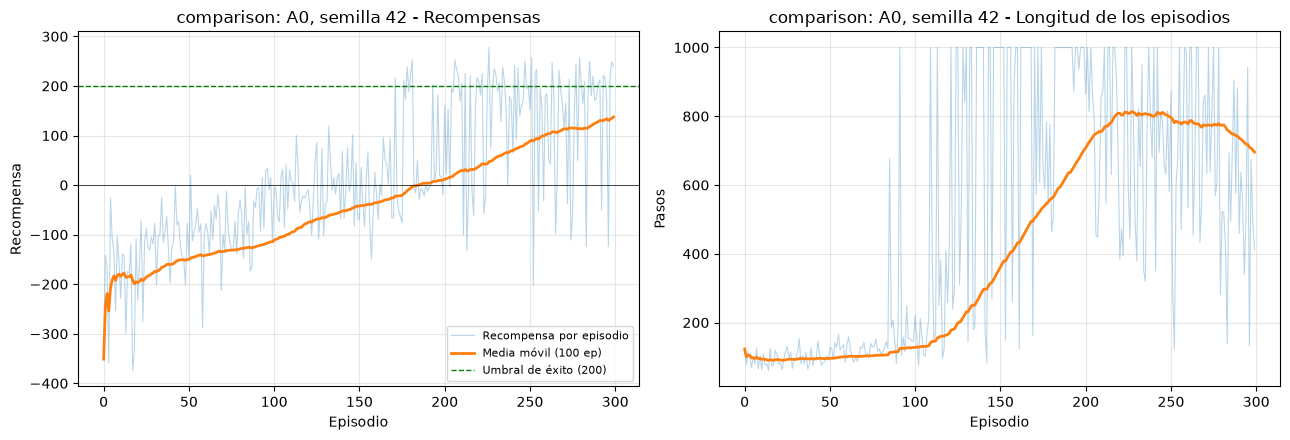

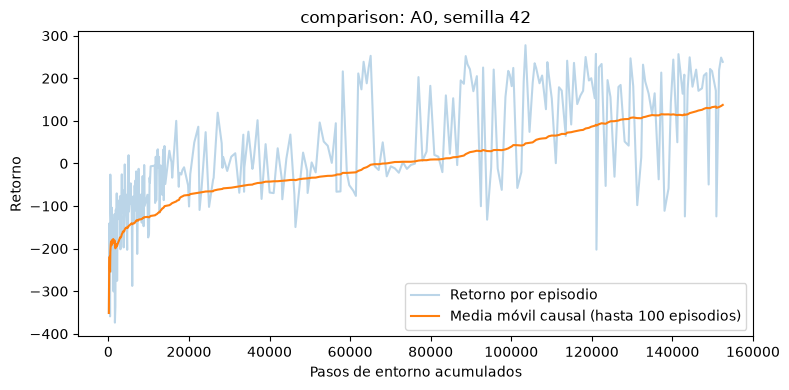

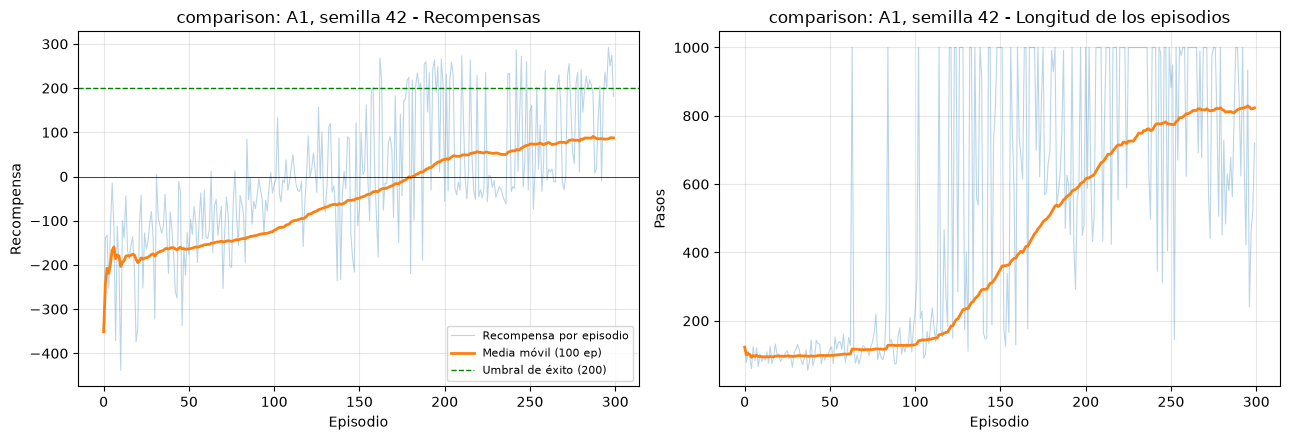

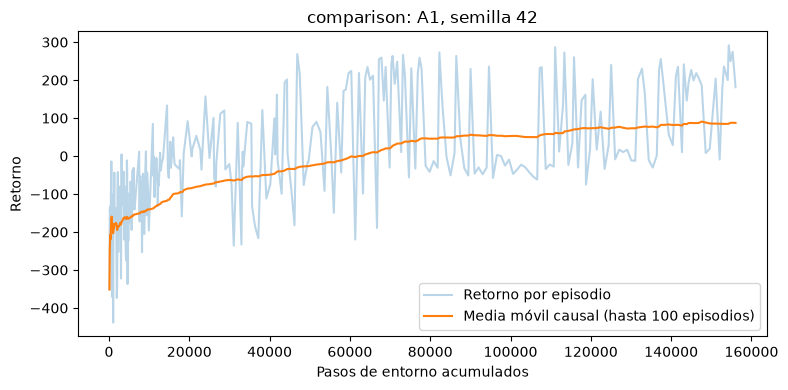

In [13]:
for (nombre, semilla), corrida in corridas.items():
    titulo = f"{MODO}: {nombre}, semilla {semilla}"
    graficar_progreso_entrenamiento(corrida["recompensas"], corrida["longitudes"], titulo, ventana=100)
    # La utilidad original se conserva; además se guarda una figura contra pasos acumulados.
    fig, ax = plt.subplots(figsize=(8, 4))
    pasos = np.cumsum(corrida["longitudes"])
    ax.plot(pasos, corrida["recompensas"], alpha=.3, label="Retorno por episodio")
    ax.plot(pasos, media_movil(corrida["recompensas"], 100), label="Media móvil causal (hasta 100 episodios)")
    ax.set(xlabel="Pasos de entorno acumulados", ylabel="Retorno", title=titulo)
    ax.legend()
    fig.tight_layout()
    fig.savefig(corrida["carpeta"] / "curve_steps.png", dpi=140)
    plt.show()


In [14]:
# Pesos guardados automáticamente; ejemplo de recarga solo para evaluación:
# config = json.loads((carpeta / "config.json").read_text())
# env = gym.make("LunarLander-v3")
# politica = AgenteDQN(env.observation_space, env.action_space,
#                     hidden_dims=tuple(config["hidden_dims"]), use_target=False)
# politica.red_q.load_state_dict(torch.load(carpeta / "online_weights.pt", map_location="cpu", weights_only=True))
# resultado = evaluar_agente(politica, env, num_episodios=200, semilla=10_000)
# env.close()
# Esto NO restaura el estado completo de entrenamiento.


## 8. Evaluación del agente entrenado

Se evalúan 200 episodios, sin exploración, sobre semillas fijas
(`10000 … 10199`). El agente aleatorio se vuelve a evaluar en la misma celda con
esas mismas semillas, de modo que ambos agentes enfrenten los mismos escenarios
iniciales.

In [15]:
# La evaluación DQN ya se guardó al terminar cada entrenamiento.
resultados_dqn = primera["resultado"]
carpeta_azar = RAIZ_RESULTADOS / "random_seed42"
carpeta_azar.mkdir(exist_ok=False)
guardar_json(carpeta_azar / "config.json", dict(mode=MODO, agent="AgenteAleatorio",
    action_seed=42, evaluation_seed=SEMILLA_EVAL, evaluation_episodes=EPISODIOS_EVAL,
    environment="LunarLander-v3", continuous=False, enable_wind=False,
    python=sys.version, packages=VERSIONES, device="cpu", torch_threads=torch.get_num_threads(),
    hardware=platform.platform(), machine=platform.machine()))
env_azar = gym.make("LunarLander-v3", continuous=False, enable_wind=False)
try:
    aleatorio = AgenteAleatorio(env_azar.action_space, semilla=42)
    resumen_azar = dict(configuration="random", training_seed=None, completed_episodes=0,
                        total_steps=0, optimizer_updates=0, training_seconds=0.)
    resultados_aleatorio_200 = evaluar_y_guardar(aleatorio, carpeta_azar, resumen_azar)
finally:
    env_azar.close()
imprimir_resultados_evaluacion(resultados_aleatorio_200, "Aleatorio")
print("\nResultados de desarrollo (desviación estándar poblacional, ddof=0):")
print("configuración / semilla | media ± std | éxitos/eval | pasos | entrenamiento / evaluación (s)")
for corrida in list(corridas.values()) + [dict(resumen=resumen_azar)]:
    r = corrida["resumen"]
    print(f"{r['configuration']} / {r['training_seed']} | {r['mean_return']:.2f} ± {r['std_return']:.2f} | "
          f"{r['successes']}/{r['evaluated']} | {r['total_steps']} | "
          f"{r['training_seconds']:.1f} / {r['evaluation_seconds']:.1f}")
print("Criterio: éxito en >10% de episodios (21/200 en la comparación).")
print("Un seed de entrenamiento no mide variabilidad entre entrenamientos.")



Aleatorio - Resultados de evaluación:
Tasa de éxito (R ≥ 200): 0.0%
Recompensa promedio: -183.17
Recompensa mediana:  -149.80
Desviación estándar: 111.96
Total de éxitos: 0 / 200

Resultados de desarrollo (desviación estándar poblacional, ddof=0):
configuración / semilla | media ± std | éxitos/eval | pasos | entrenamiento / evaluación (s)
A0 / 42 | 167.22 ± 103.12 | 113/200 | 152500 | 31.6 / 6.8
A1 / 42 | 142.05 ± 102.47 | 65/200 | 156033 | 34.3 / 8.3
random / None | -183.17 ± 111.96 | 0/200 | 0 | 0.0 / 0.6
Criterio: éxito en >10% de episodios (21/200 en la comparación).
Un seed de entrenamiento no mide variabilidad entre entrenamientos.


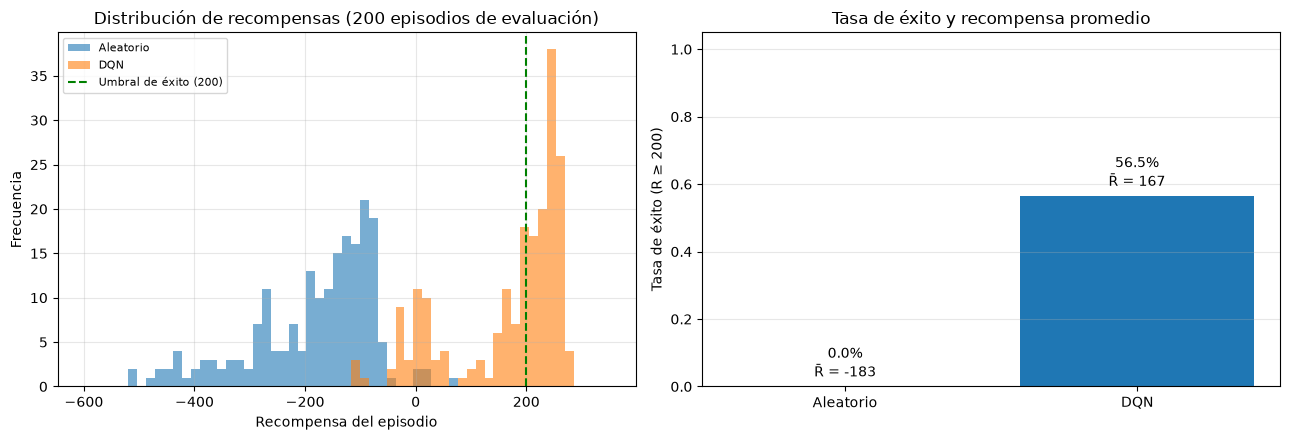

Tasa de éxito DQN:       56.5%
Tasa de éxito Aleatorio: 0.0%
Mejora en recompensa promedio: 350.4 puntos

Desglose de los 200 episodios del DQN:
  R ≥  200:  56.5%
  R ≥  150:  72.0%
  R ≥  100:  75.5%
  R ≥    0:  89.5%
  Episodios que se estrellan (R < -50): 2.0%


In [16]:
# Comparación gráfica: DQN vs. agente aleatorio
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

bins = np.linspace(-600, 350, 60)
ax1.hist(resultados_aleatorio_200['recompensas_totales'], bins=bins, alpha=0.6, label="Aleatorio")
ax1.hist(resultados_dqn['recompensas_totales'], bins=bins, alpha=0.6, label="DQN")
ax1.axvline(UMBRAL_EXITO, color='green', linestyle='--', label="Umbral de éxito (200)")
ax1.set_title(f"Distribución de recompensas ({EPISODIOS_EVAL} episodios de evaluación)")
ax1.set_xlabel("Recompensa del episodio")
ax1.set_ylabel("Frecuencia")
ax1.legend(fontsize=8)
ax1.grid(True, alpha=0.3)

nombres = ["Aleatorio", "DQN"]
tasas = [resultados_aleatorio_200['tasa_exito'], resultados_dqn['tasa_exito']]
promedios = [resultados_aleatorio_200['recompensa_promedio'], resultados_dqn['recompensa_promedio']]

barras = ax2.bar(nombres, tasas, color=['tab:gray', 'tab:blue'])
ax2.set_ylim(0, 1.05)
ax2.set_ylabel("Tasa de éxito (R ≥ 200)")
ax2.set_title("Tasa de éxito y recompensa promedio")
for barra, tasa, promedio in zip(barras, tasas, promedios):
    ax2.text(barra.get_x() + barra.get_width() / 2, tasa + 0.03,
             f"{tasa:.1%}\nR̄ = {promedio:.0f}", ha='center', fontsize=10)
ax2.grid(True, axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

print(f"Tasa de éxito DQN:       {resultados_dqn['tasa_exito']:.1%}")
print(f"Tasa de éxito Aleatorio: {resultados_aleatorio_200['tasa_exito']:.1%}")
print(f"Mejora en recompensa promedio: "
      f"{resultados_dqn['recompensa_promedio'] - resultados_aleatorio_200['recompensa_promedio']:.1f} puntos")

# El umbral de 200 es un corte tajante: desglose de la cola de la distribución.
r_dqn = resultados_dqn['recompensas_totales']
print(f"\nDesglose de los {EPISODIOS_EVAL} episodios del DQN:")
for corte in (200, 150, 100, 0):
    print(f"  R ≥ {corte:4d}: {(r_dqn >= corte).mean():6.1%}")
print(f"  Episodios que se estrellan (R < -50): {(r_dqn < -50).mean():.1%}")


## 9. Visualización de la política aprendida

Se corren 10 episodios sin exploración sobre semillas sorteadas, sin elegir
los que salieron bien, y se arma un GIF con los diez en una grilla. Cada cuadro
muestra al terminar la recompensa del episodio, en verde si llegó al umbral de éxito
y en rojo si no.

In [17]:
from PIL import Image, ImageDraw
from IPython.display import Image as MostrarImagen, display

ANCHO_CUADRO, ALTO_CUADRO = 240, 160

def _correr_episodio_render(agente, env, semilla, salto):
    """Corre un episodio renderizando y devuelve (cuadros, recompensa, pasos)."""
    estado, _ = env.reset(seed=semilla)
    cuadros, recompensa_total, paso = [], 0.0, 0
    while True:
        if paso % salto == 0:
            cuadros.append(Image.fromarray(env.render()).resize((ANCHO_CUADRO, ALTO_CUADRO)))
        estado, recompensa, terminado, truncado, _ = env.step(agente.elegir_accion(estado, explorar=False))
        recompensa_total += recompensa
        paso += 1
        if terminado or truncado:
            cuadros.append(Image.fromarray(env.render()).resize((ANCHO_CUADRO, ALTO_CUADRO)))
            break
    return cuadros, recompensa_total, paso


def _rotular(cuadro, recompensa, umbral):
    """Escribe la recompensa final sobre el cuadro: verde si es éxito, rojo si no."""
    cuadro = cuadro.copy()
    color = (40, 170, 70) if recompensa >= umbral else (210, 50, 50)
    ImageDraw.Draw(cuadro).text((6, 4), f"R = {recompensa:.0f}", fill=color)
    return cuadro


def grabar_episodios(agente, ruta_gif='aterrizaje_dqn.gif', semillas=range(10_000, 10_010),
                     columnas=5, salto=3, umbral=UMBRAL_EXITO):
    """Corre un episodio sin exploración por semilla y guarda un GIF con todos en
    una grilla. Los episodios que terminan antes quedan quietos en su último cuadro,
    rotulado con la recompensa obtenida."""
    env = gym.make('LunarLander-v3', render_mode='rgb_array')
    episodios = []
    try:
        for semilla in semillas:
            cuadros, recompensa_total, pasos = _correr_episodio_render(agente, env, semilla, salto)
            print(f"  semilla {semilla}: {pasos:4d} pasos, recompensa {recompensa_total:7.1f}")
            cuadros[-1] = _rotular(cuadros[-1], recompensa_total, umbral)
            episodios.append((cuadros, recompensa_total))
    finally:
        env.close()

    filas = -(-len(episodios) // columnas)
    largo = max(len(cuadros) for cuadros, _ in episodios)
    fotogramas = []
    for t in range(largo):
        lienzo = Image.new('RGB', (columnas * ANCHO_CUADRO, filas * ALTO_CUADRO), 'white')
        for i, (cuadros, _) in enumerate(episodios):
            lienzo.paste(cuadros[min(t, len(cuadros) - 1)],
                         ((i % columnas) * ANCHO_CUADRO, (i // columnas) * ALTO_CUADRO))
        fotogramas.append(lienzo)
    fotogramas[0].save(ruta_gif, save_all=True, append_images=fotogramas[1:], duration=50, loop=0)

    recompensas = np.array([r for _, r in episodios])
    print(f"\n{(recompensas >= umbral).sum()}/{len(recompensas)} episodios exitosos, "
          f"recompensa media {recompensas.mean():.1f} → {ruta_gif}")
    return ruta_gif, recompensas


if RUN_GIF:
    # Semillas sorteadas, no elegidas: el GIF muestra los diez episodios salgan como salgan.
    semillas_gif = np.random.default_rng(SEMILLA).integers(20_000, 30_000, size=10).tolist()
    ruta, _ = grabar_episodios(agente_dqn, semillas=semillas_gif)
    display(MostrarImagen(filename=ruta))
else:
    print("GIF opcional omitido; activar RUN_GIF para generarlo.")


GIF opcional omitido; activar RUN_GIF para generarlo.


## 10. Qué aprendió la política

Analicen la política aprendida utilizando cortes con valores fijos en algunas
dimensiones para validar lo aprendido.


In [18]:
# Pendiente para la entrega final, fuera del checkpoint del jueves.
if RUN_FINAL_EXPERIMENTS:
    raise NotImplementedError("Pendiente: cortes de la política; implementar antes de la entrega final")
else:
    print("Sección diferida: cortes de la política (RUN_FINAL_EXPERIMENTS=False)")


Sección diferida: cortes de la política (RUN_FINAL_EXPERIMENTS=False)


## 11. Estudio de ablación

Las secciones anteriores muestran que el DQN completo funciona, pero no *cuánto*
aporta cada una de sus piezas. Una **ablación** responde eso: se reentrena el
agente desde cero desactivando (o degradando) un componente por vez y se mide
cuánto cae el desempeño respecto de la configuración completa.

Comparen el DQN completo contra, como mínimo, tres variantes correspondientes a
quitar características de DQN. Cada configuración se entrena con varias semillas y
se evalúa sobre las mismas semillas de evaluación, sin exploración. Reporten para
cada variante la recompensa de evaluación por semilla y comparen contra el DQN
completo con un test estadístico adecuado.


In [19]:
# Pendiente para la entrega final, fuera del checkpoint del jueves.
if RUN_FINAL_EXPERIMENTS:
    raise NotImplementedError("Pendiente: estudio de ablación; implementar antes de la entrega final")
else:
    print("Sección diferida: estudio de ablación (RUN_FINAL_EXPERIMENTS=False)")


Sección diferida: estudio de ablación (RUN_FINAL_EXPERIMENTS=False)
